# Week 8 — Day 3: Lead Scoring Model (Classification) & Explainability
## AI Property Valuation & Lead Scoring Platform for Real Estate
**Platform Architecture:** Machine Learning (LightGBM/CatBoost) • Imbalanced Data Handling • K-Means Personas • SHAP Explainable AI • MLflow Model Registry • Week 7 Agent Tool Calling  
**Scenario:** The sales team has 200 new leads and time to call only 40. Your model decides who gets called first with zero wasted calls and explains its predictions in English & UrduLish.

---

### Day 3 Core Deliverables:
- **Task 1 — Classification Models:** Dummy baseline, Logistic Regression, Random Forest, XGBoost, LightGBM, CatBoost
- **Task 2 — Handling Imbalanced Data:** No balancing vs Class weights vs SMOTE vs Threshold tuning (with proof why accuracy is misleading)
- **Task 3 — Comprehensive Evaluation:** Precision, Recall, F1, ROC-AUC, PR-AUC, Confusion Matrix, Calibration Curve, Precision@Top-20%, and Business Cost Optimization ($C_{\text{FN}} = 400\text{k PKR}$ vs $C_{\text{FP}} = 1.2\text{k PKR}$)
- **Task 4 — Lead Segmentation & Customer Personas:** 🔥 Hot (1-hr SLA), 🌤 Warm (24-hr SLA), ❄️ Cold (drip), plus K-Means discovery of 4 customer personas
- **Task 5 — Explainability with SHAP (Both Models):** Global beeswarm, Local waterfall, Plain-language English & UrduLish reason generator, and Fairness/Bias audit across City and Lead Source
- **Week 7 Agent Integration:** `lead_scoring_tool` in `week7-RE_Agent/day5-langgraph-agent`


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# Setup paths
NOTEBOOK_DIR = Path.cwd()
DAY3_DIR = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR
WEEK8_DIR = DAY3_DIR.parent
SRC_DIR = DAY3_DIR / "src"
REPORTS_DIR = DAY3_DIR / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
MODELS_DIR = DAY3_DIR / "models"

if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print("Environment configured successfully!")


Environment configured successfully!


## Step 1: Stratified Data Splits & Feature Pipeline
We load the 70/15/15 stratified train, validation, and test splits ($N=2,520$ train, $N=540$ val, $N=540$ test) with a 25.2% base conversion rate.
All 7 leakage columns (`converted`, `converted_binary`, `lead_id`, `client_name`, `phone`, `budget_raw`, `budget_pkr_normalized`) are safely stripped before column transformation.


In [2]:
from lead_models import load_lead_splits, prepare_feature_matrices

train_df, val_df, test_df = load_lead_splits()
X_train, y_train, X_val, y_val, X_test, y_test, preprocessor, feature_names = prepare_feature_matrices(
    train_df, val_df, test_df
)

print(f"Engineered Features Count: {len(feature_names)}")
print(f"Train Shape: {X_train.shape} | Positive Rate: {np.mean(y_train):.1%}")
print(f"Val Shape:   {X_val.shape}   | Positive Rate: {np.mean(y_val):.1%}")
print(f"Test Shape:  {X_test.shape}  | Positive Rate: {np.mean(y_test):.1%}")


Engineered Features Count: 38
Train Shape: (2520, 38) | Positive Rate: 25.2%
Val Shape:   (540, 38)   | Positive Rate: 25.4%
Test Shape:  (540, 38)  | Positive Rate: 25.2%


## Step 2: Model Comparison & Imbalance Handling (Tasks 1 & 2)
### Why Accuracy is Misleading:
The Dummy (Most Frequent) classifier achieves **74.81% accuracy** simply by predicting `0` for every lead. However, its Recall and Precision are **0.0%**, missing every single closing deal!

We benchmark:
1. Baseline: Dummy Classifier, Logistic Regression
2. Tree Ensembles: Random Forest, XGBoost, LightGBM, CatBoost
3. Imbalance Strategies: No Balancing vs Class Weights vs SMOTE vs Threshold Tuning


In [4]:
from lead_models import train_and_compare_models, compare_imbalance_strategies

models_df, fitted_models = train_and_compare_models(X_train, y_train, X_test, y_test)
print("=== CLASSIFICATION MODELS COMPARISON (TEST SET) ===")
display(models_df)

strat_df, strat_models = compare_imbalance_strategies(X_train, y_train, X_val, y_val, X_test, y_test)
print("=== IMBALANCE HANDLING STRATEGIES (LIGHTGBM) ===")
display(strat_df)


=== CLASSIFICATION MODELS COMPARISON (TEST SET) ===


,model_name,accuracy,precision,recall,f1,roc_auc,pr_auc,brier_score,precision_top20,lift_top20
0,Logistic Regression,0.7926,0.6579,0.3676,0.4717,0.7889,0.5925,0.1468,0.6296,2.50
1,Random Forest,0.7907,0.6716,0.3309,0.4433,0.7732,0.5643,0.1508,0.5926,2.35
2,XGBoost,0.7833,0.6044,0.4044,0.4846,0.7762,0.5611,0.1532,0.5926,2.35
3,CatBoost,0.7833,0.6145,0.3750,0.4658,0.7665,0.5497,0.1548,0.5741,2.28
4,LightGBM,0.7889,0.6222,0.4118,0.4956,0.7648,0.5460,0.1566,0.5926,2.35
5,Dummy (Most Frequent),0.7481,0.0000,0.0000,0.0000,0.5000,0.2519,0.2519,0.3148,1.25


=== IMBALANCE HANDLING STRATEGIES (LIGHTGBM) ===


,strategy,decision_threshold,accuracy,precision,recall,f1,roc_auc,pr_auc,precision_top20,lift_top20
0,1. No Balancing,0.50,0.7889,0.6222,0.4118,0.4956,0.7648,0.5460,0.5926,2.35
1,2. Class Weights (scale_pos_weight=2.96),0.50,0.7407,0.4884,0.6176,0.5455,0.7710,0.5619,0.6111,2.43
2,3. SMOTE Over-sampling,0.50,0.7722,0.5644,0.4191,0.4810,0.7549,0.5424,0.5833,2.32
3,4. Threshold Tuned (t*=0.37),0.37,0.7685,0.5396,0.5515,0.5455,0.7648,0.5460,0.5926,2.35


## Step 3: Evaluation, Calibration & Business Cost Optimization (Task 3)
### Scenario: 200 Leads, SDR Time to Call Only 40
We evaluate:
- ROC Curves and Precision-Recall Curves (PR-AUC is the gold standard under imbalance)
- Precision@Top-20% and Lift over random calling
- Calibration Reliability Diagrams (Brier Score)
- **Business Cost Optimization Curve:**
  $$\text{Total Cost}(t) = \text{FN}(t) \times C_{\text{FN}} + \text{FP}(t) \times C_{\text{FP}}$$
  where $C_{\text{FN}} = 400,000\text{ PKR}$ (lost deal commission) and $C_{\text{FP}} = 1,200\text{ PKR}$ (wasted 15-minute SDR call).


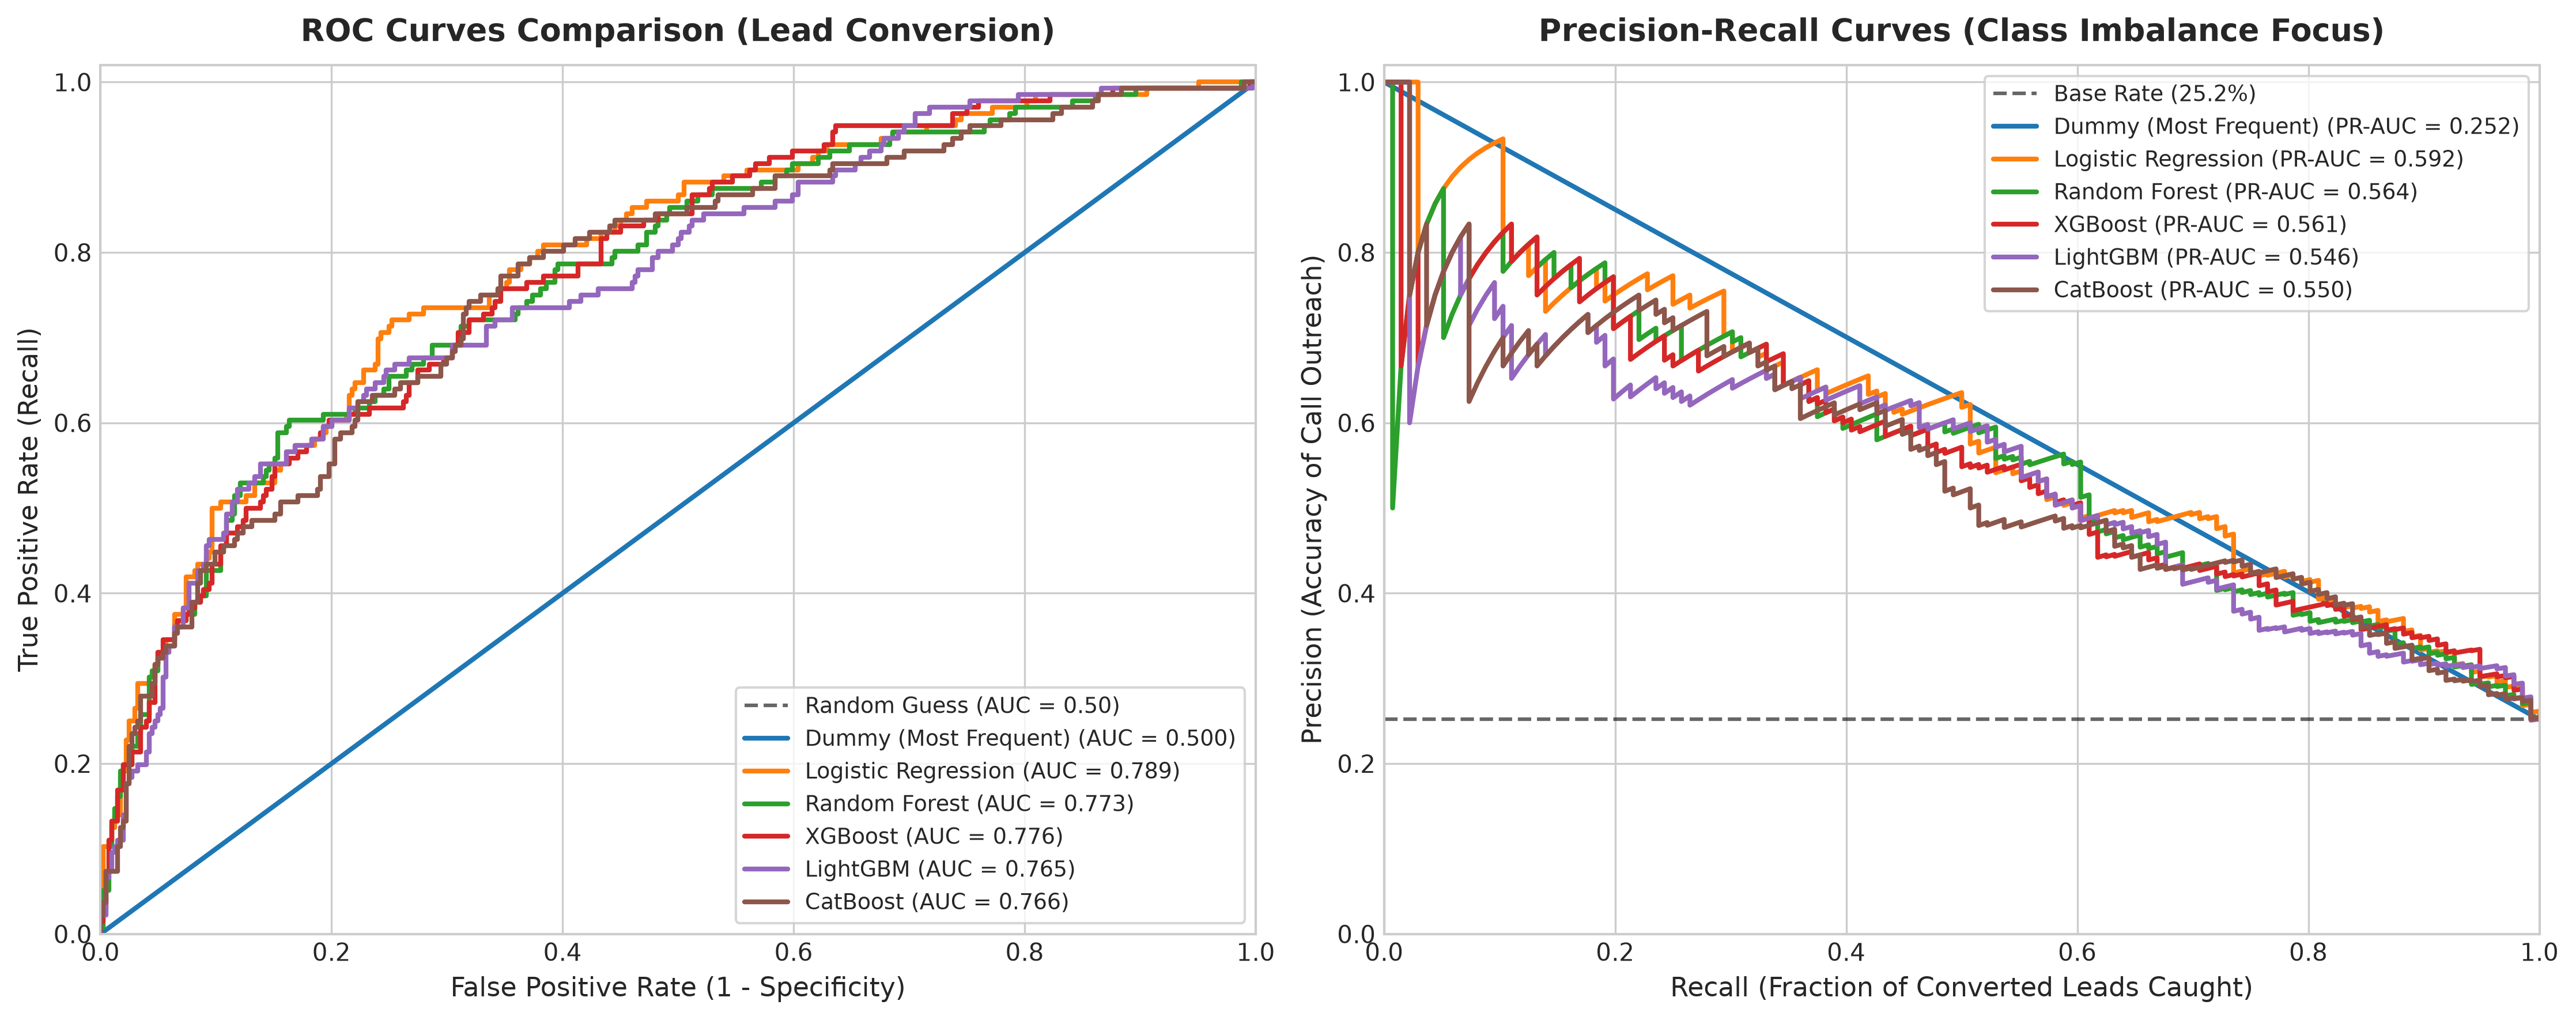

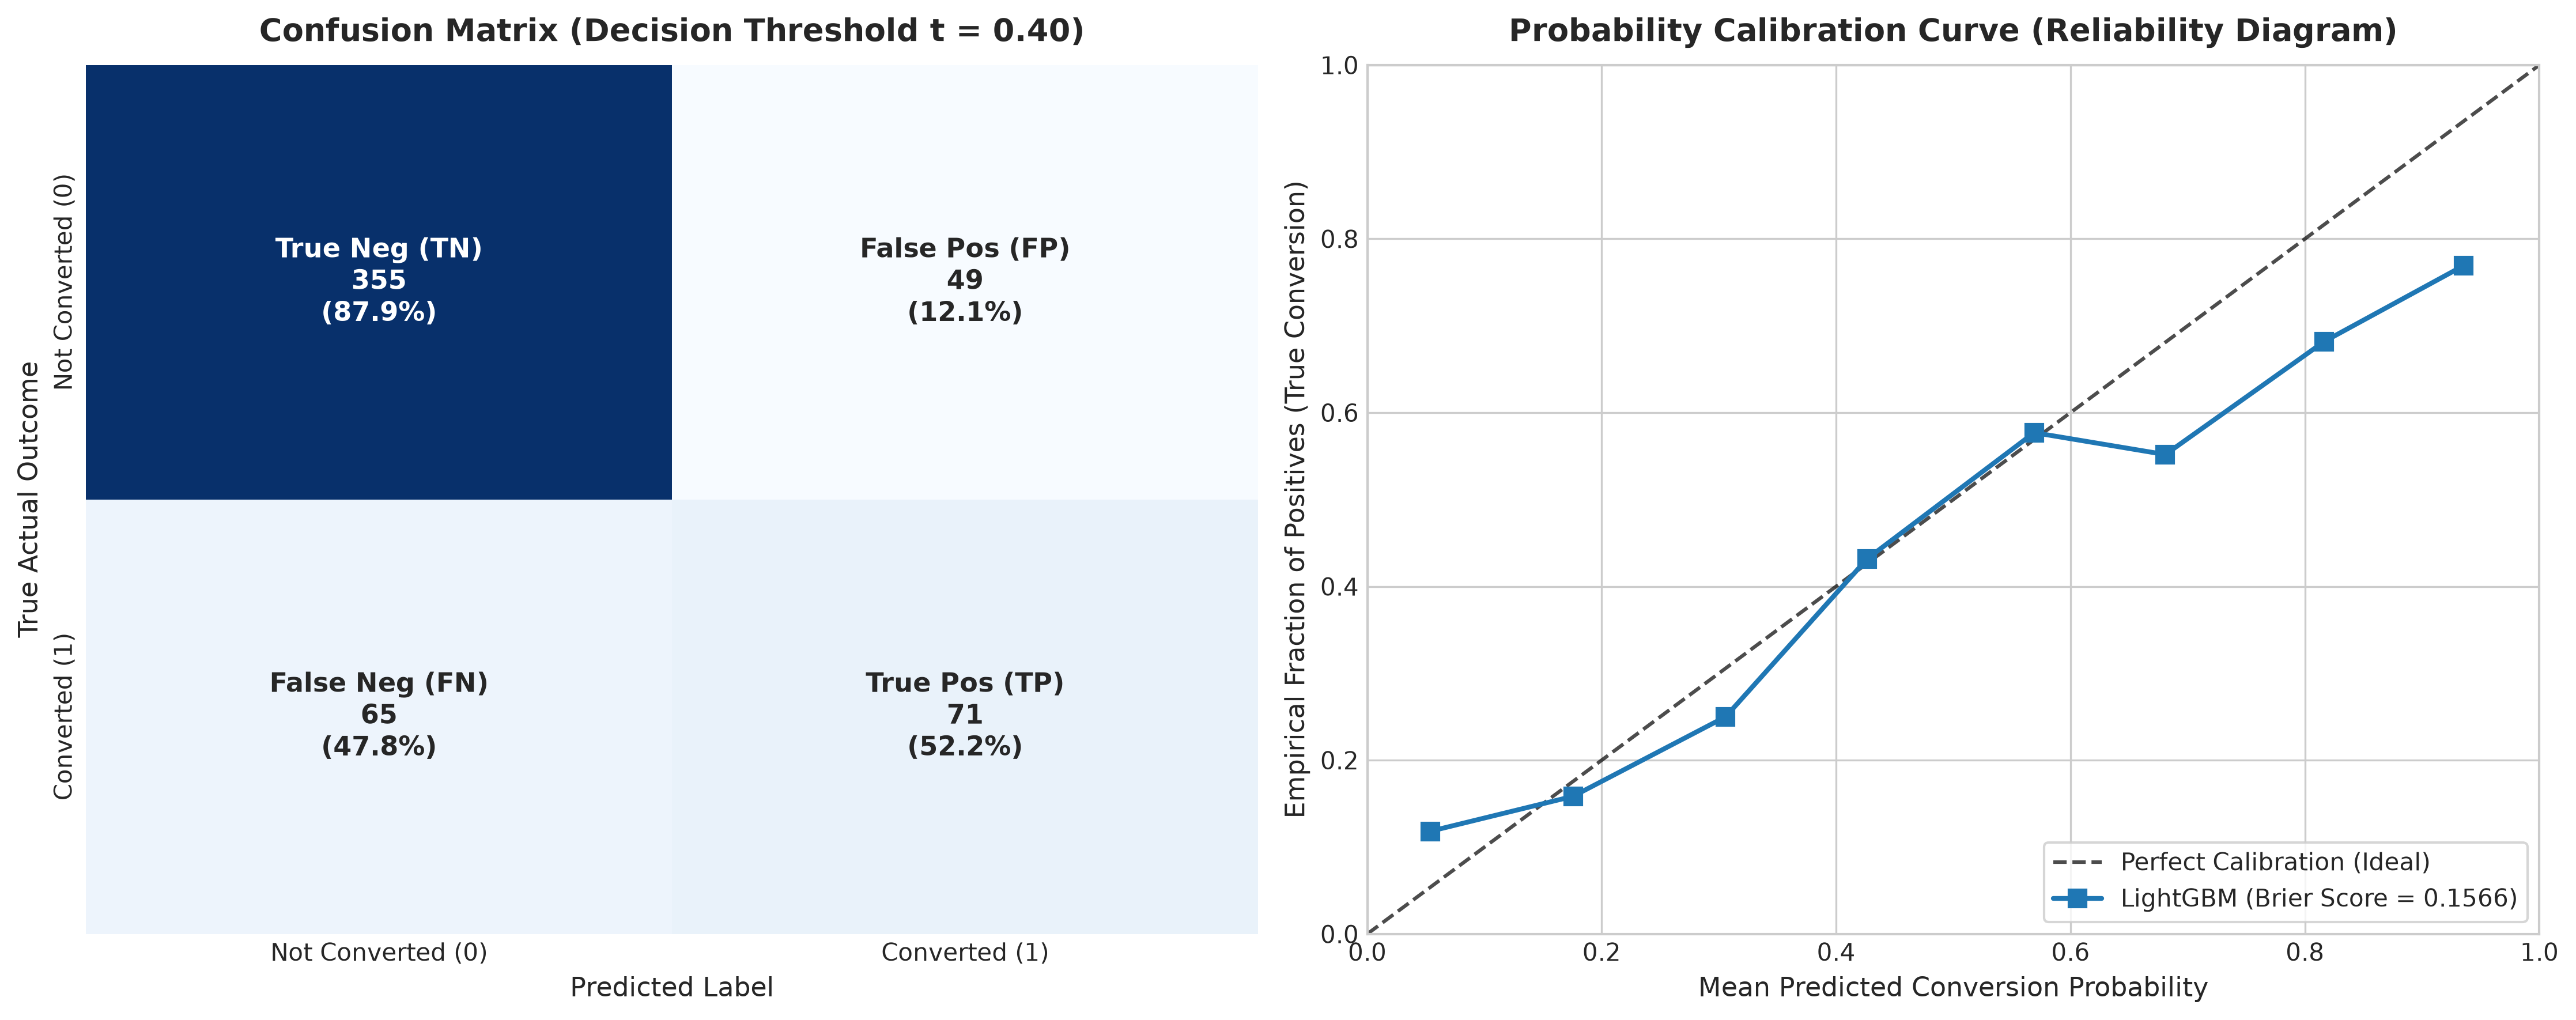

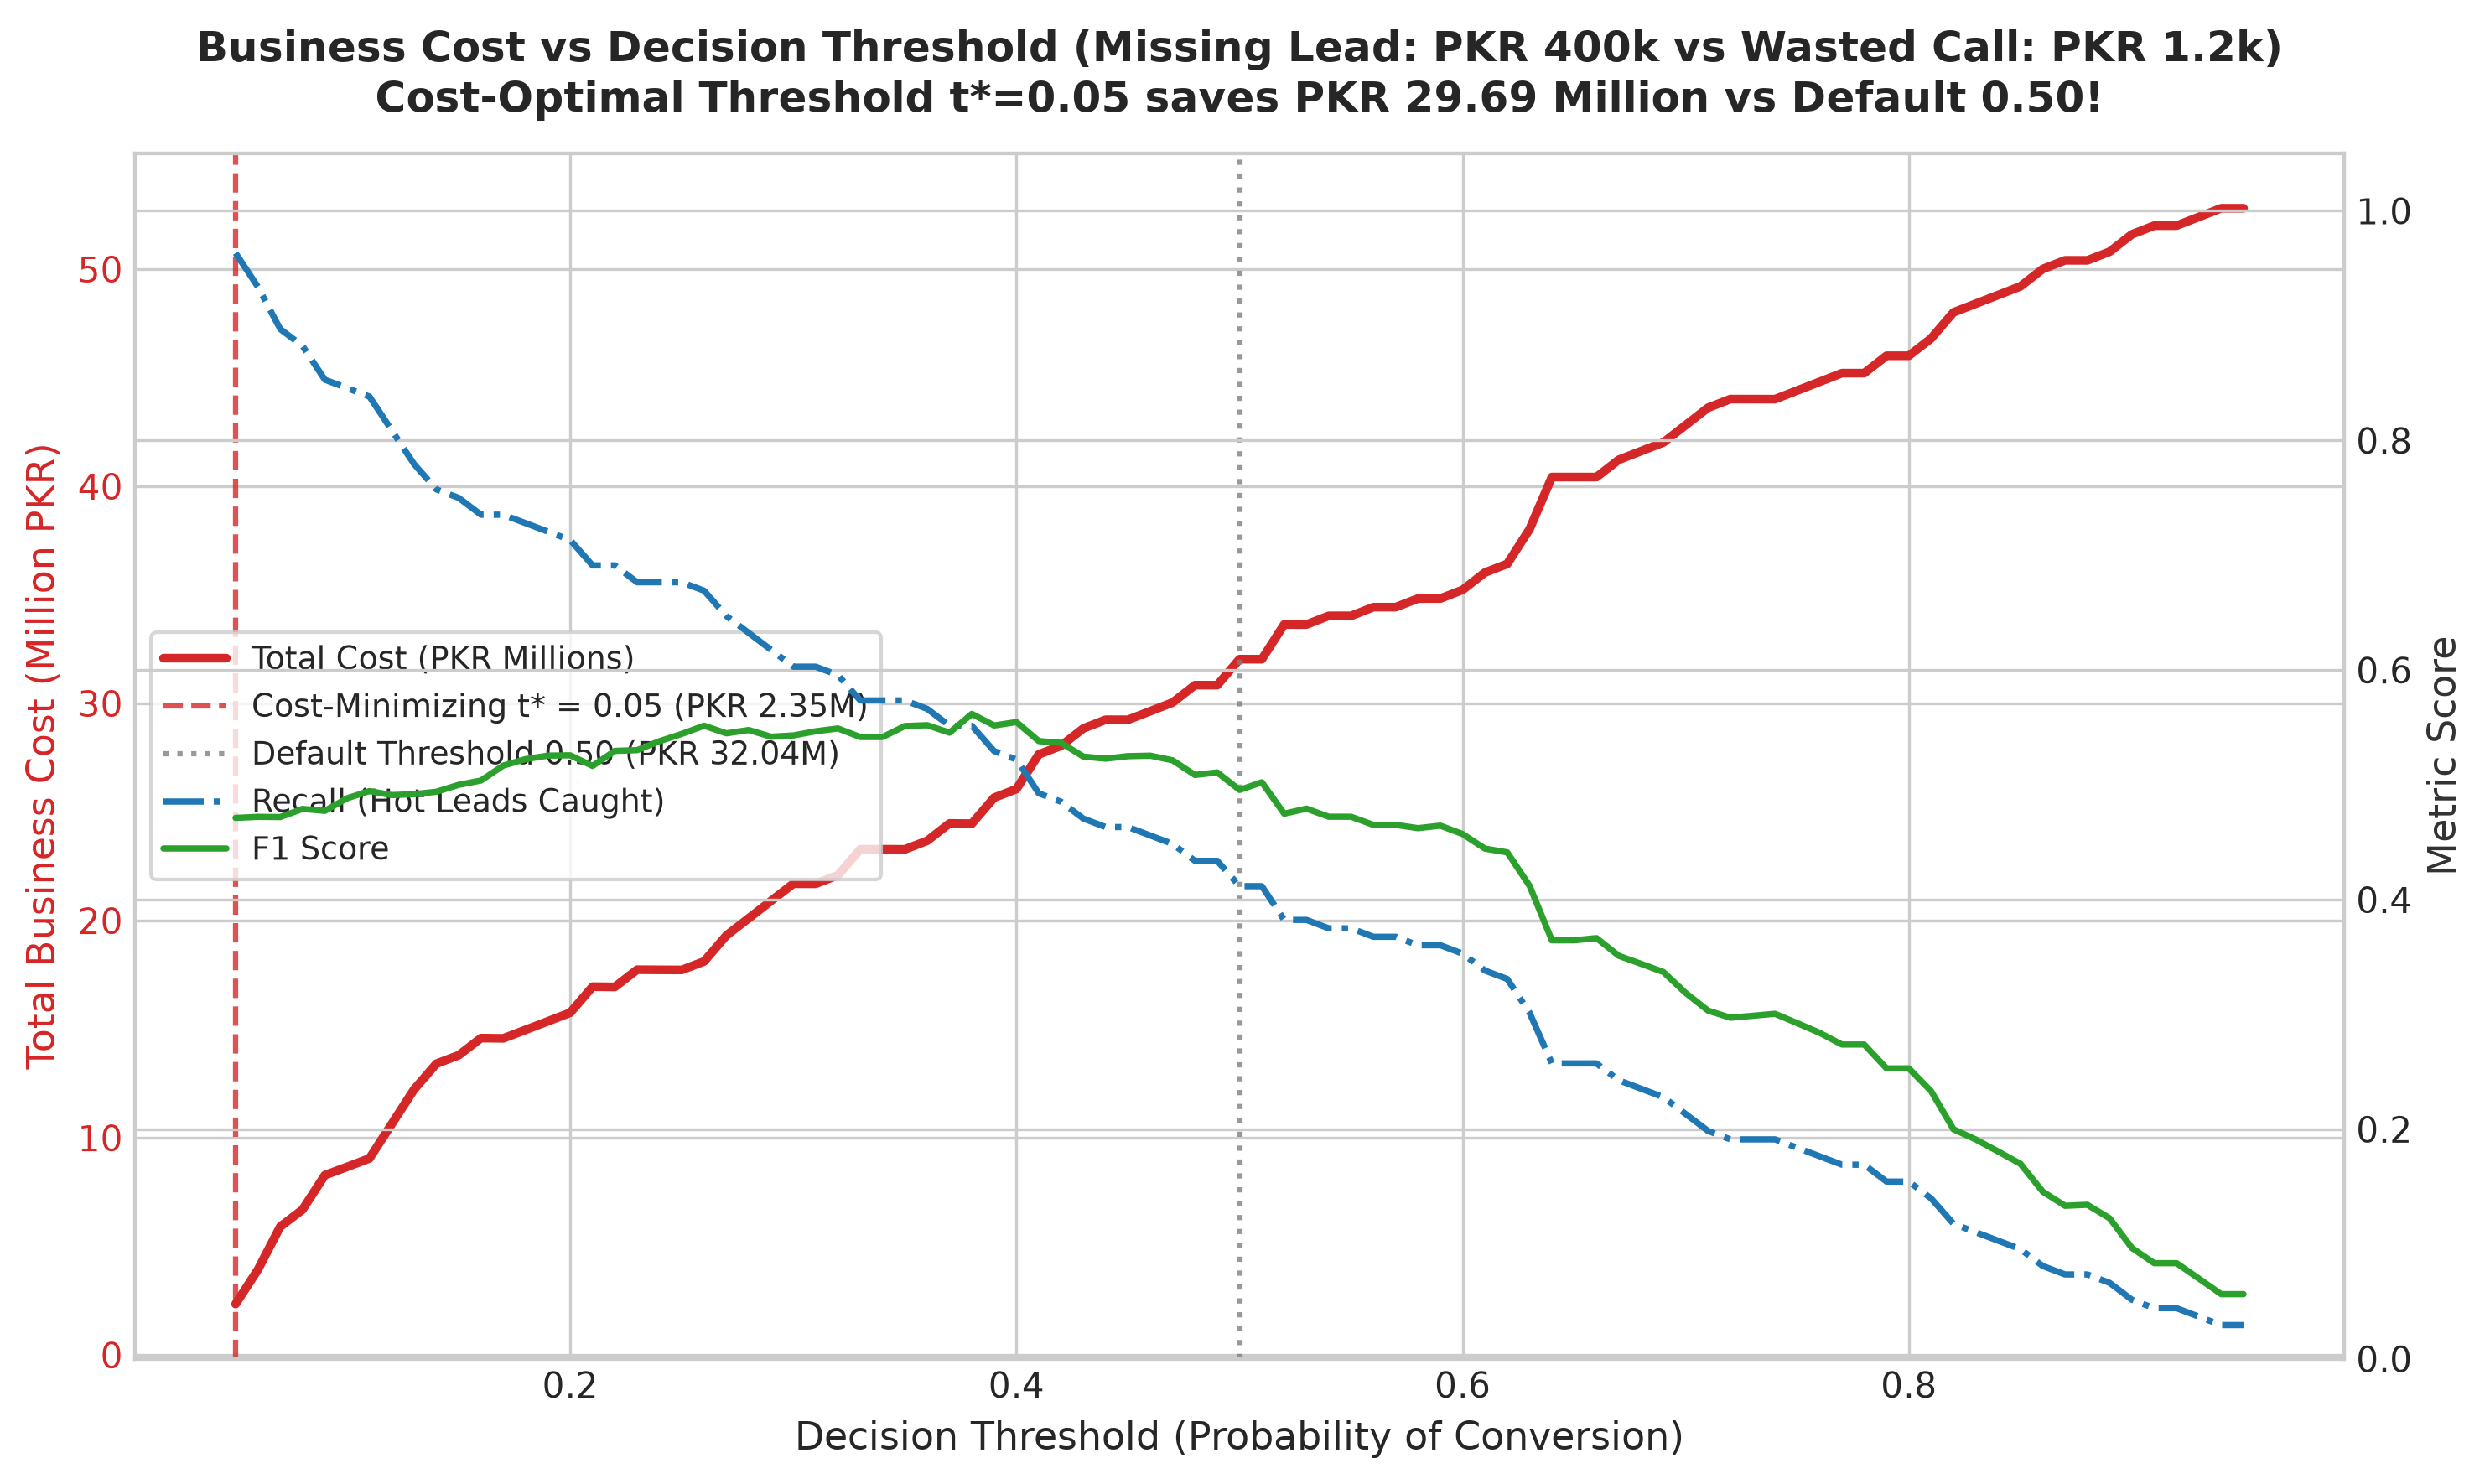

In [5]:
from IPython.display import Image, display

# Display Figures 01, 02, and 03
display(Image(filename=str(FIGURES_DIR / "01_imbalance_and_model_roc_pr_curves.png")))
display(Image(filename=str(FIGURES_DIR / "02_confusion_matrices_and_calibration.png")))
display(Image(filename=str(FIGURES_DIR / "03_business_cost_threshold_curve.png")))


## Step 4: Customer Persona Discovery via K-Means Clustering (Task 4)
Unsupervised clustering on behavioral engagement and financial capacity reveals 4 natural real estate customer personas:
1. **High-Net-Worth / Overseas Investor:** Mean Budget ~8.5 Cr PKR, Buy purpose, rapid WhatsApp response
2. **Serious First-Time Homebuyer:** Mean Budget ~1.8 Cr PKR, highest engagement (4.4 calls, visit booked), 49.9% actual conversion rate
3. **Casual Window Shoppers / Speculators:** Low engagement, no visit booked, slower response


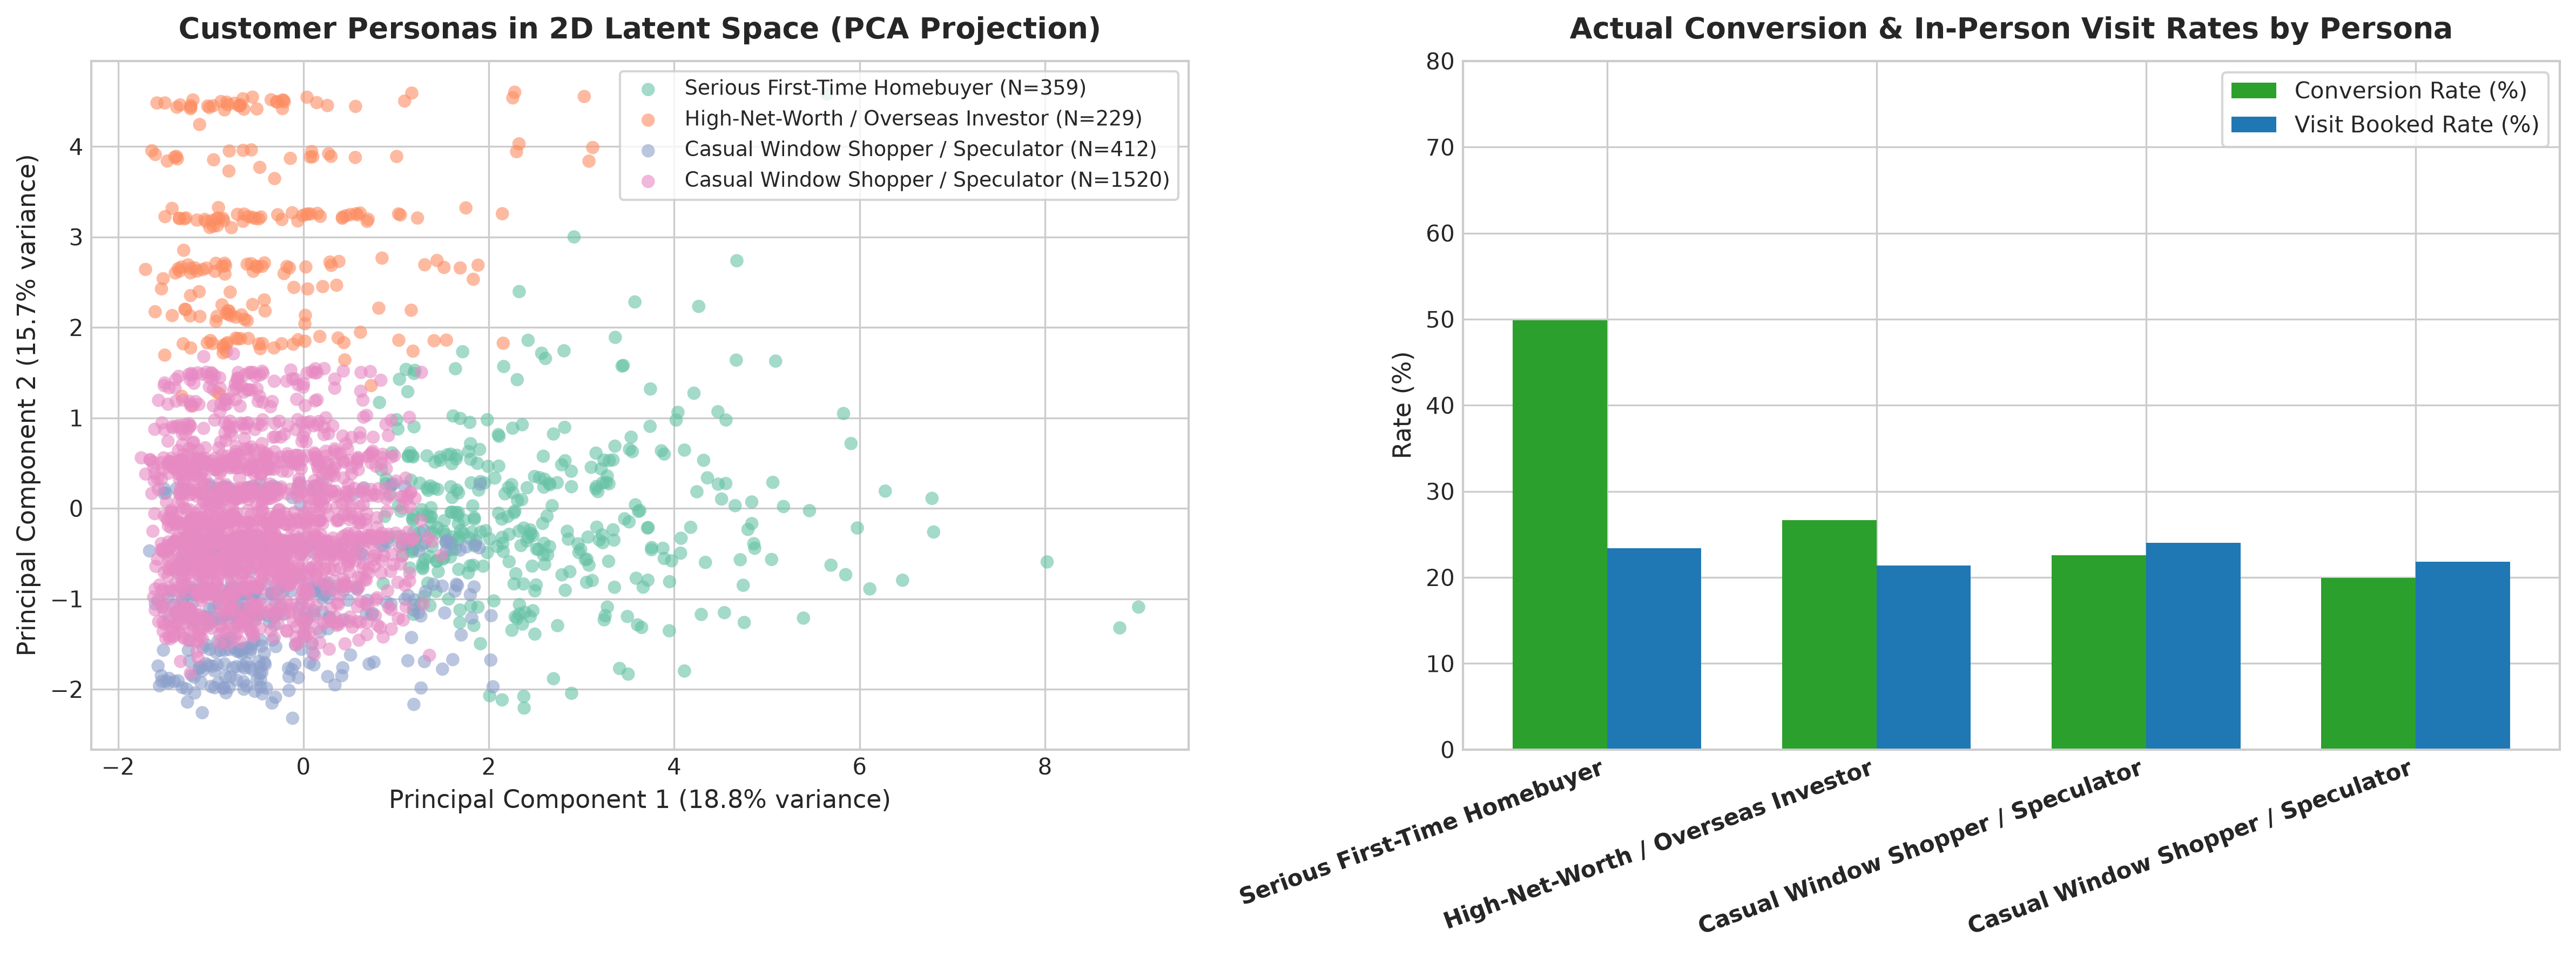

,cluster,persona_title,mean_budget_display,mean_calls,visit_booked_rate,actual_conversion_rate
0,0,Serious First-Time Homebuyer,1.80 Cr PKR,4.359331,0.233983,0.498607
1,1,High-Net-Worth / Overseas Investor,8.48 Cr PKR,2.489083,0.213974,0.266376
2,2,Casual Window Shopper / Speculator,1.40 Cr PKR,2.366505,0.240291,0.225728
3,3,Casual Window Shopper / Speculator,1.43 Cr PKR,2.343421,0.218421,0.199342


In [6]:
display(Image(filename=str(FIGURES_DIR / "04_customer_personas_clustering.png")))

personas_df = pd.read_csv(REPORTS_DIR / "customer_personas_summary.csv")
display(personas_df[["cluster", "persona_title", "mean_budget_display", "mean_calls", "visit_booked_rate", "actual_conversion_rate"]])


## Step 5: Explainability with SHAP for Both Models (Task 5)
We provide complete transparency with TreeExplainer SHAP for **both**:
1. **Lead Scoring Model:** Global beeswarm and local waterfall showing why a lead is Hot/Warm/Cold
2. **Property Valuation Model (Day 2 CatBoost):** Global beeswarm and local waterfall explaining price drivers


=== LEAD SCORING SHAP EXPLANATIONS ===


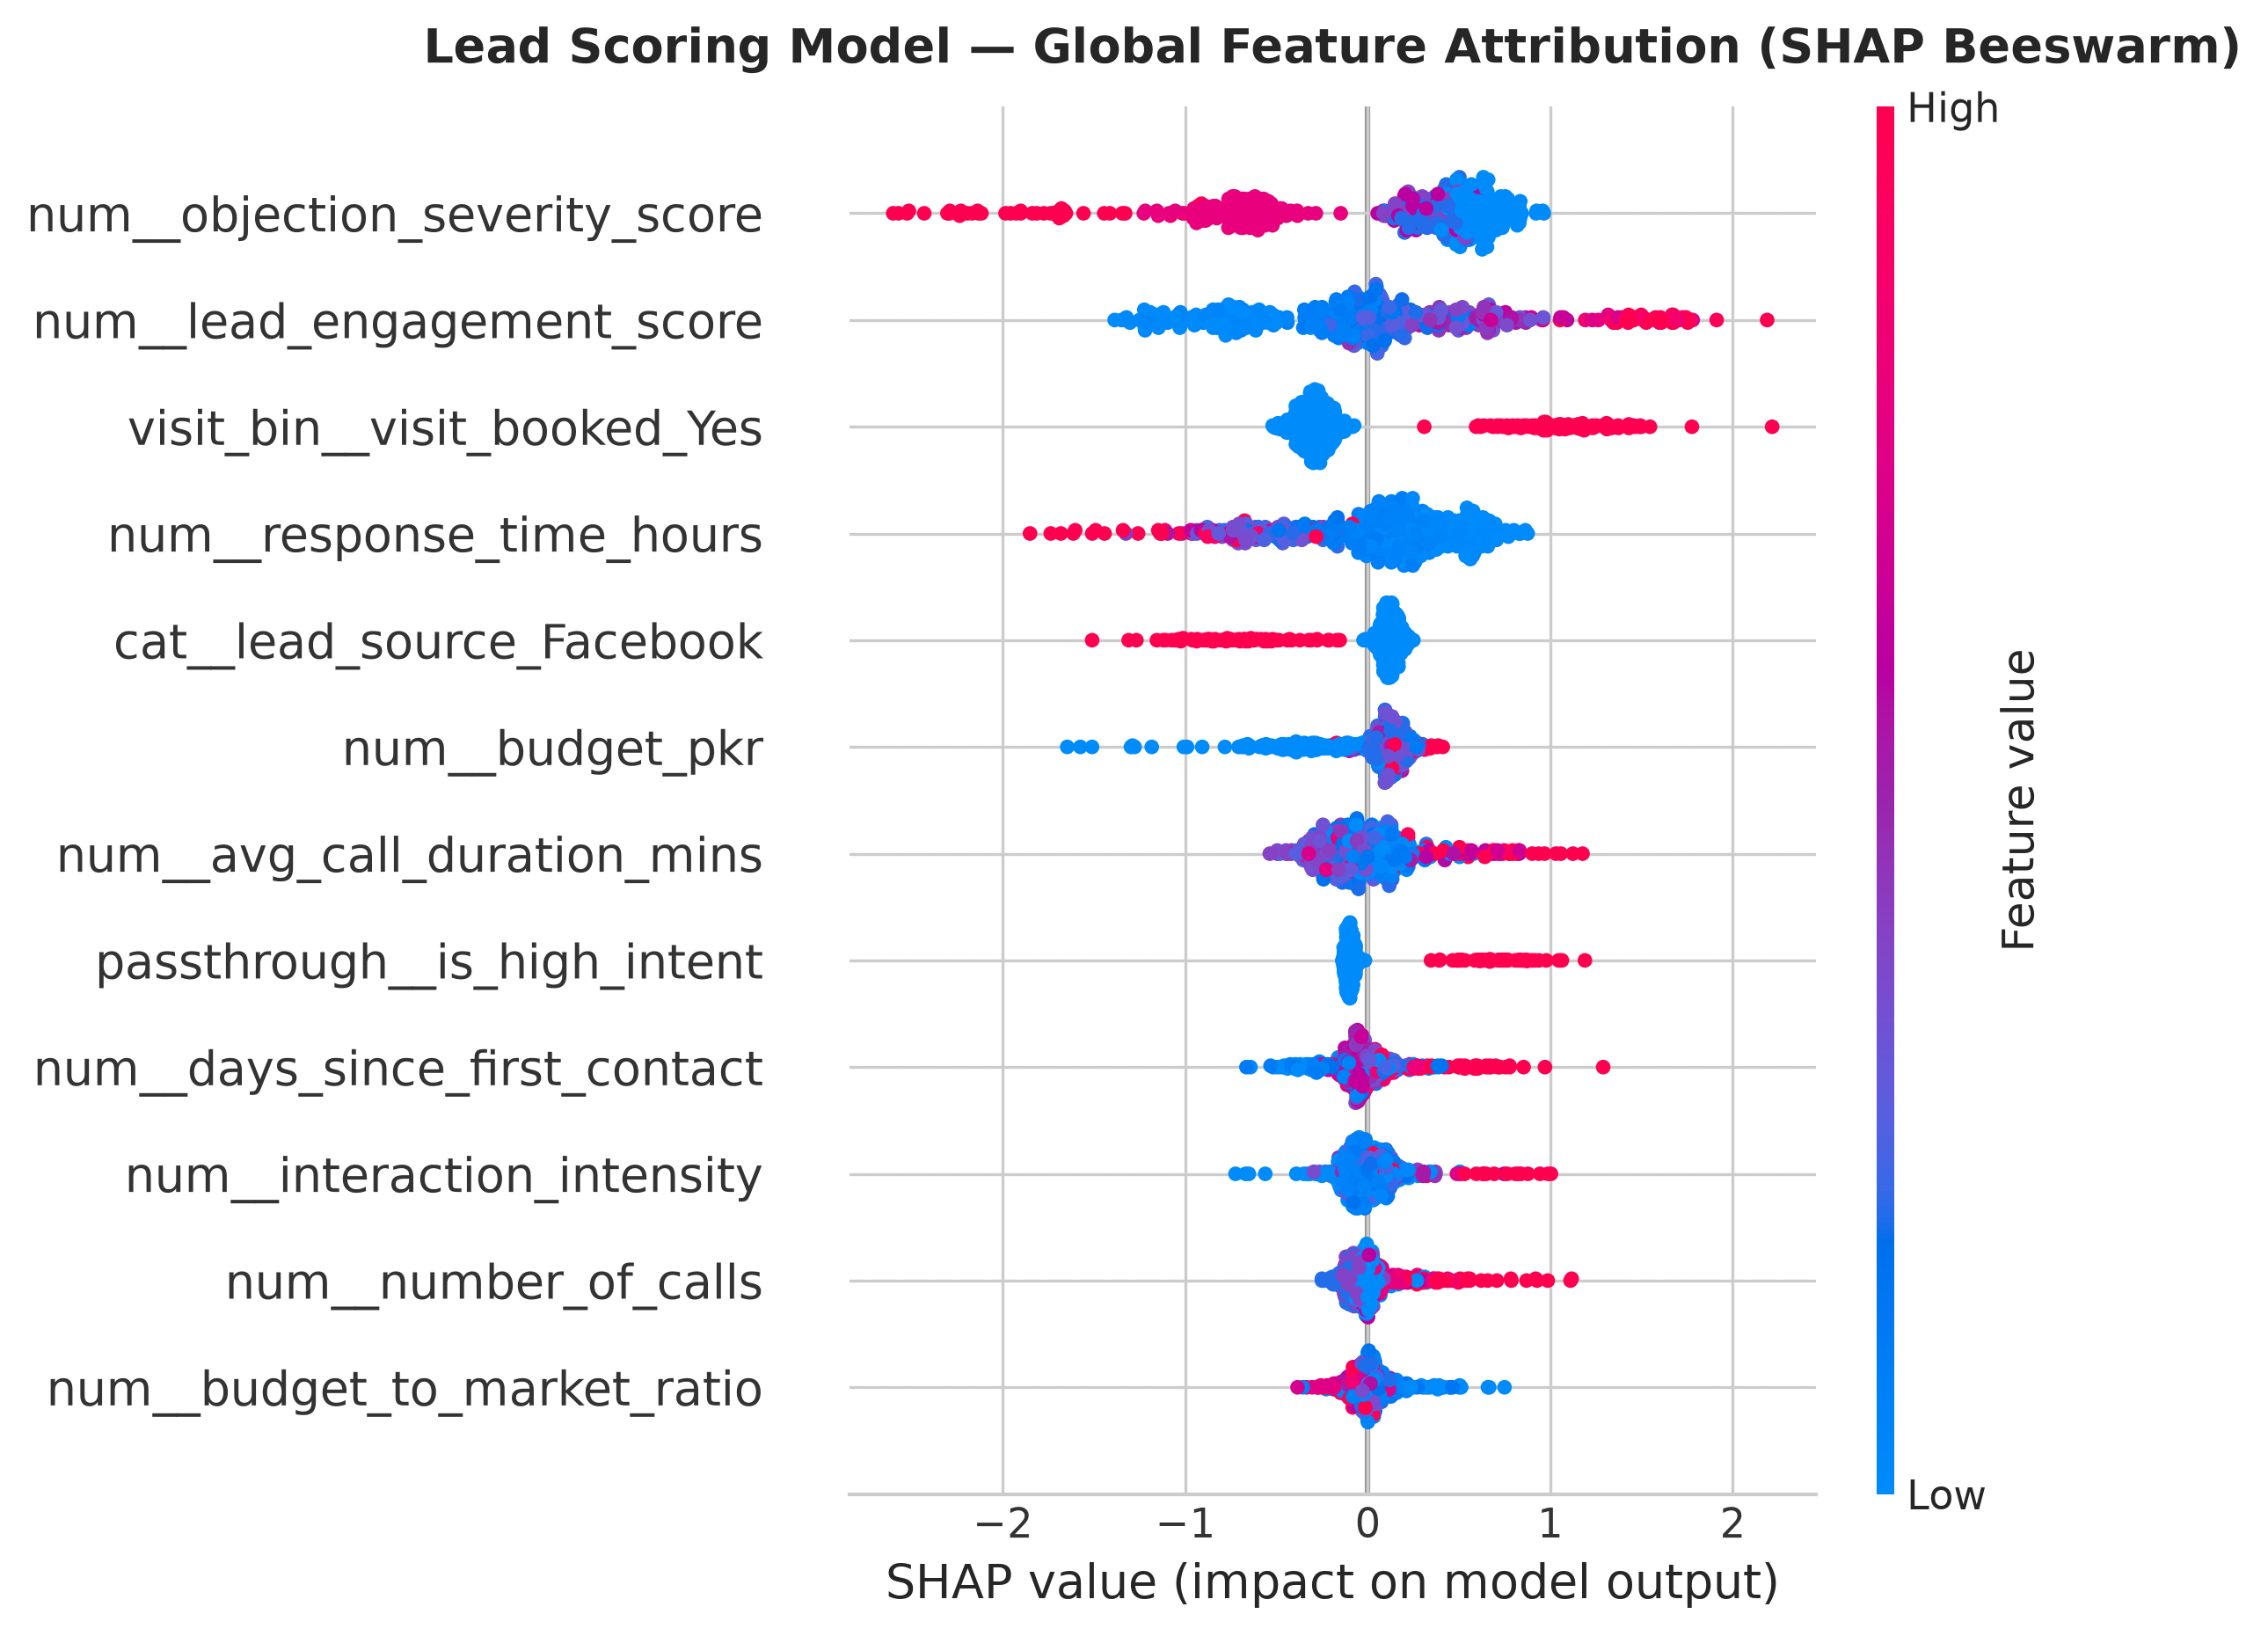

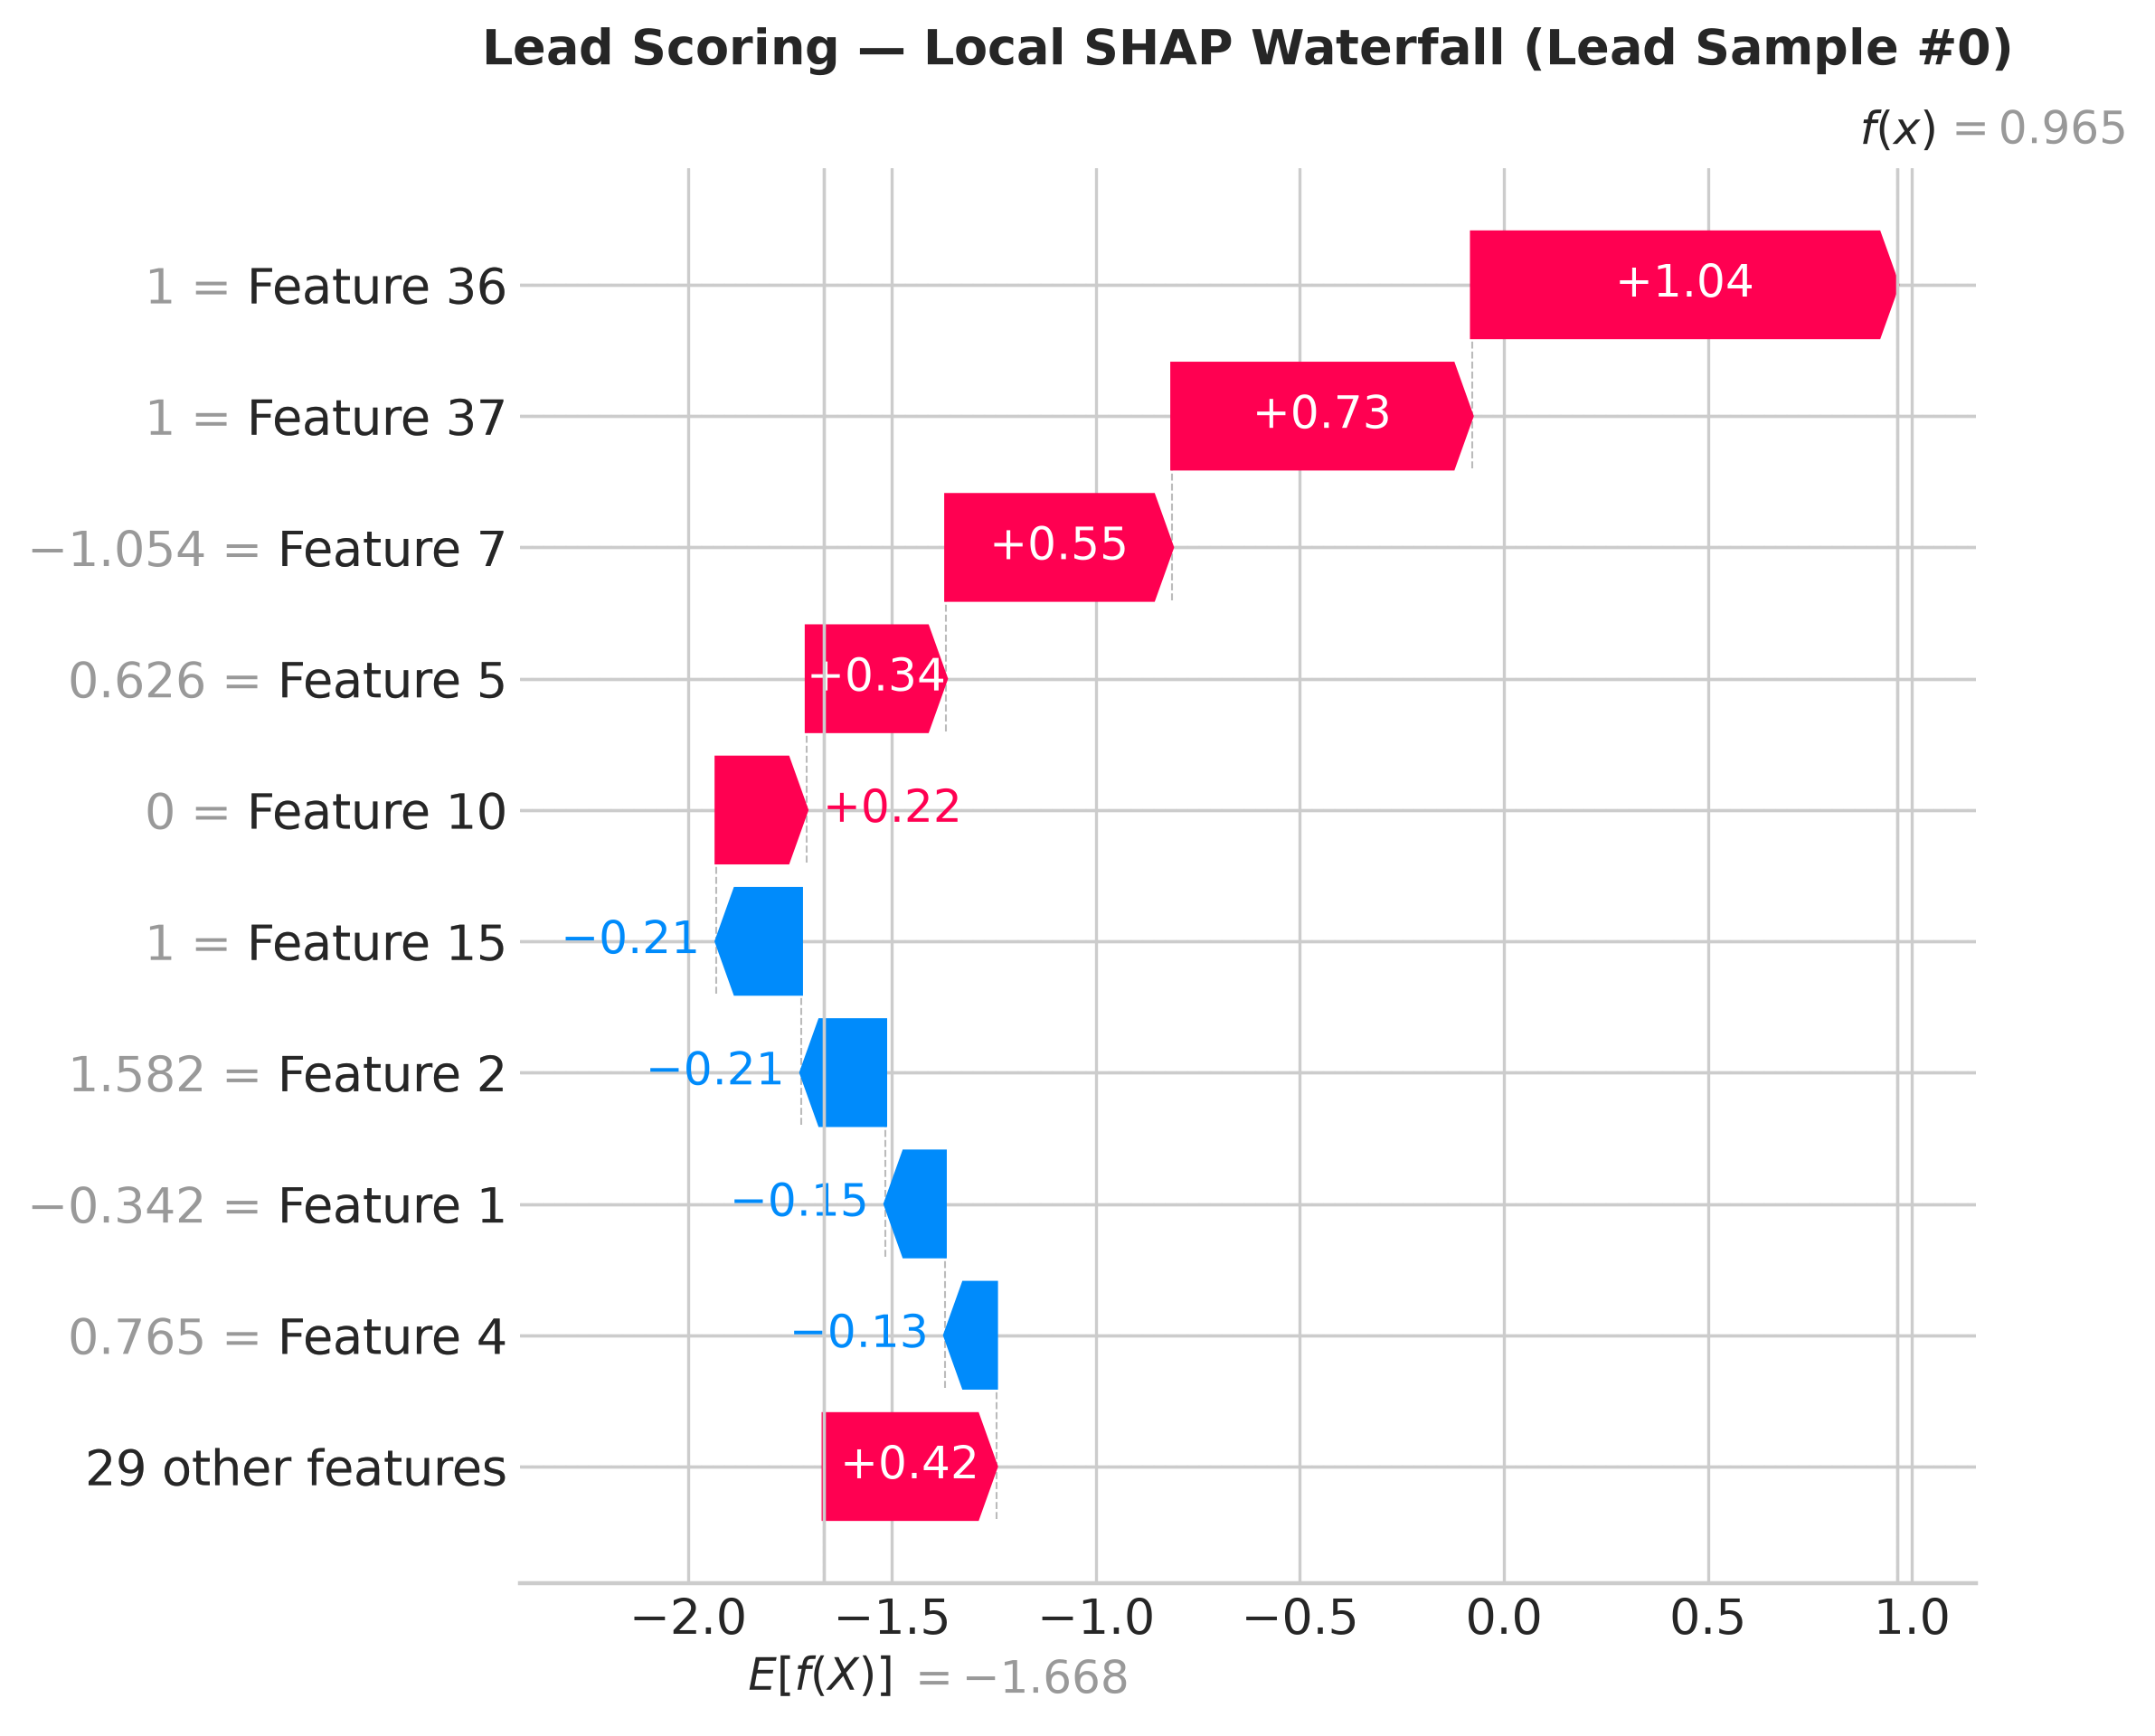

=== PROPERTY VALUATION SHAP EXPLANATIONS ===


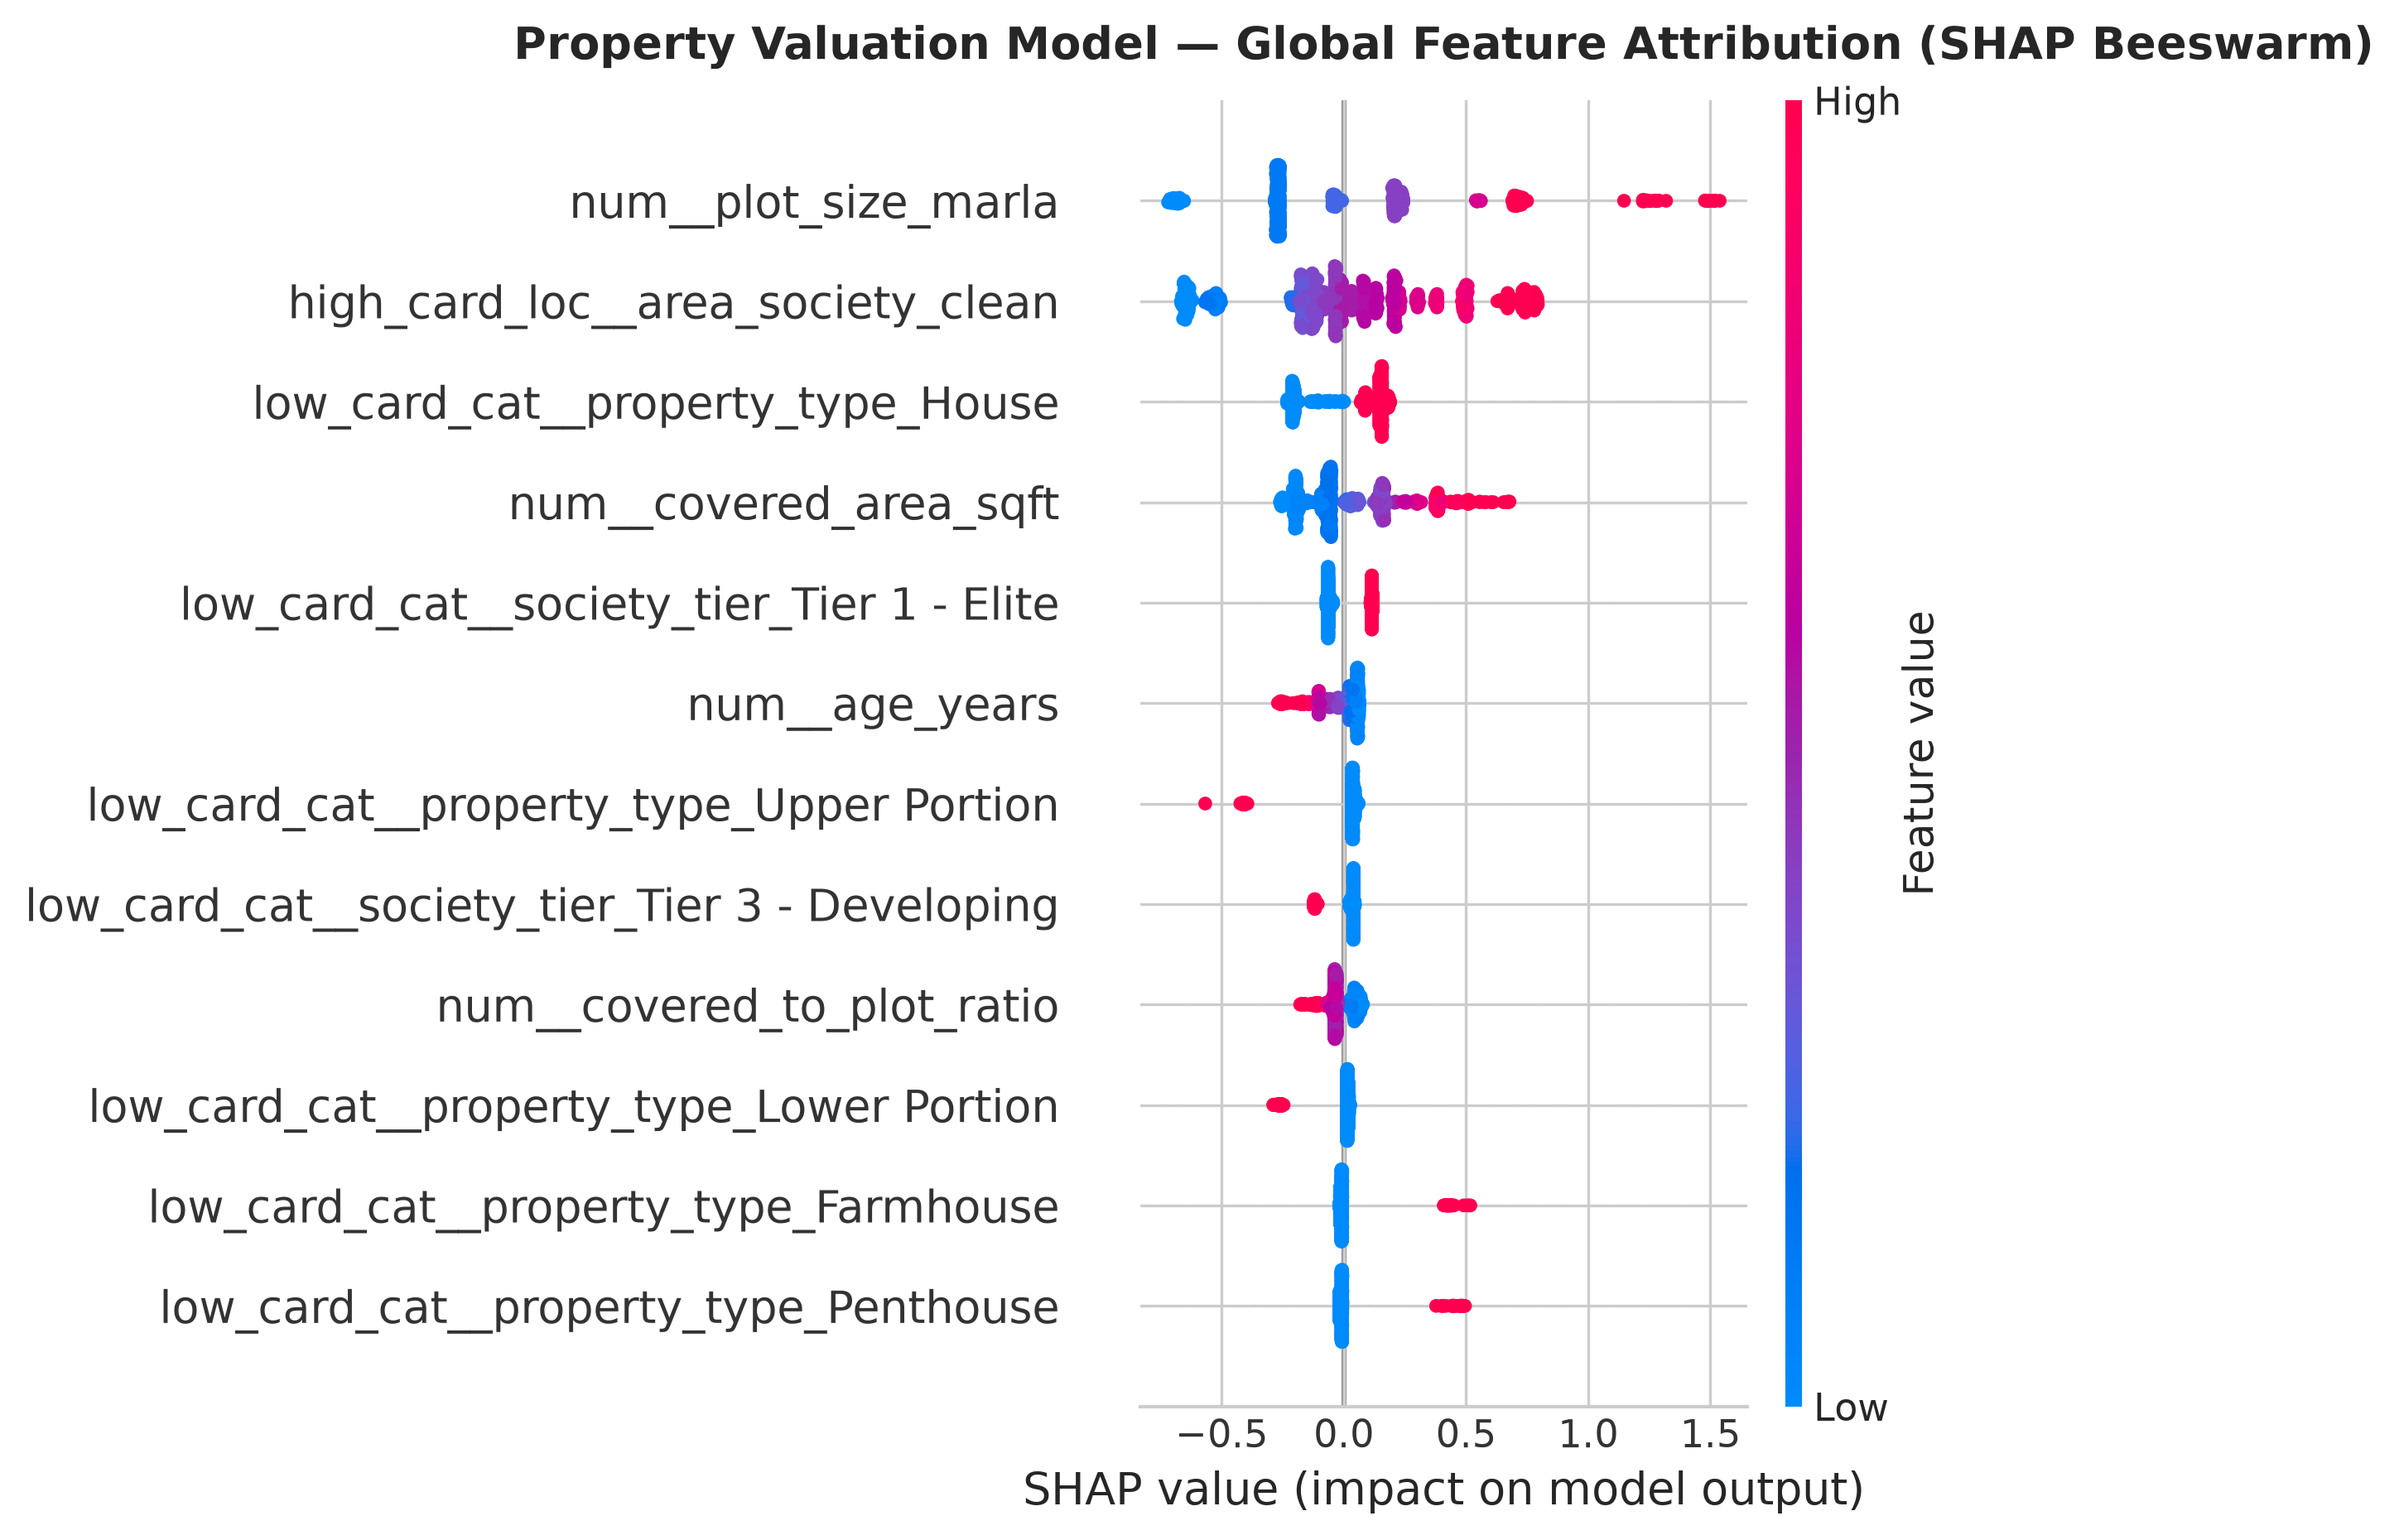

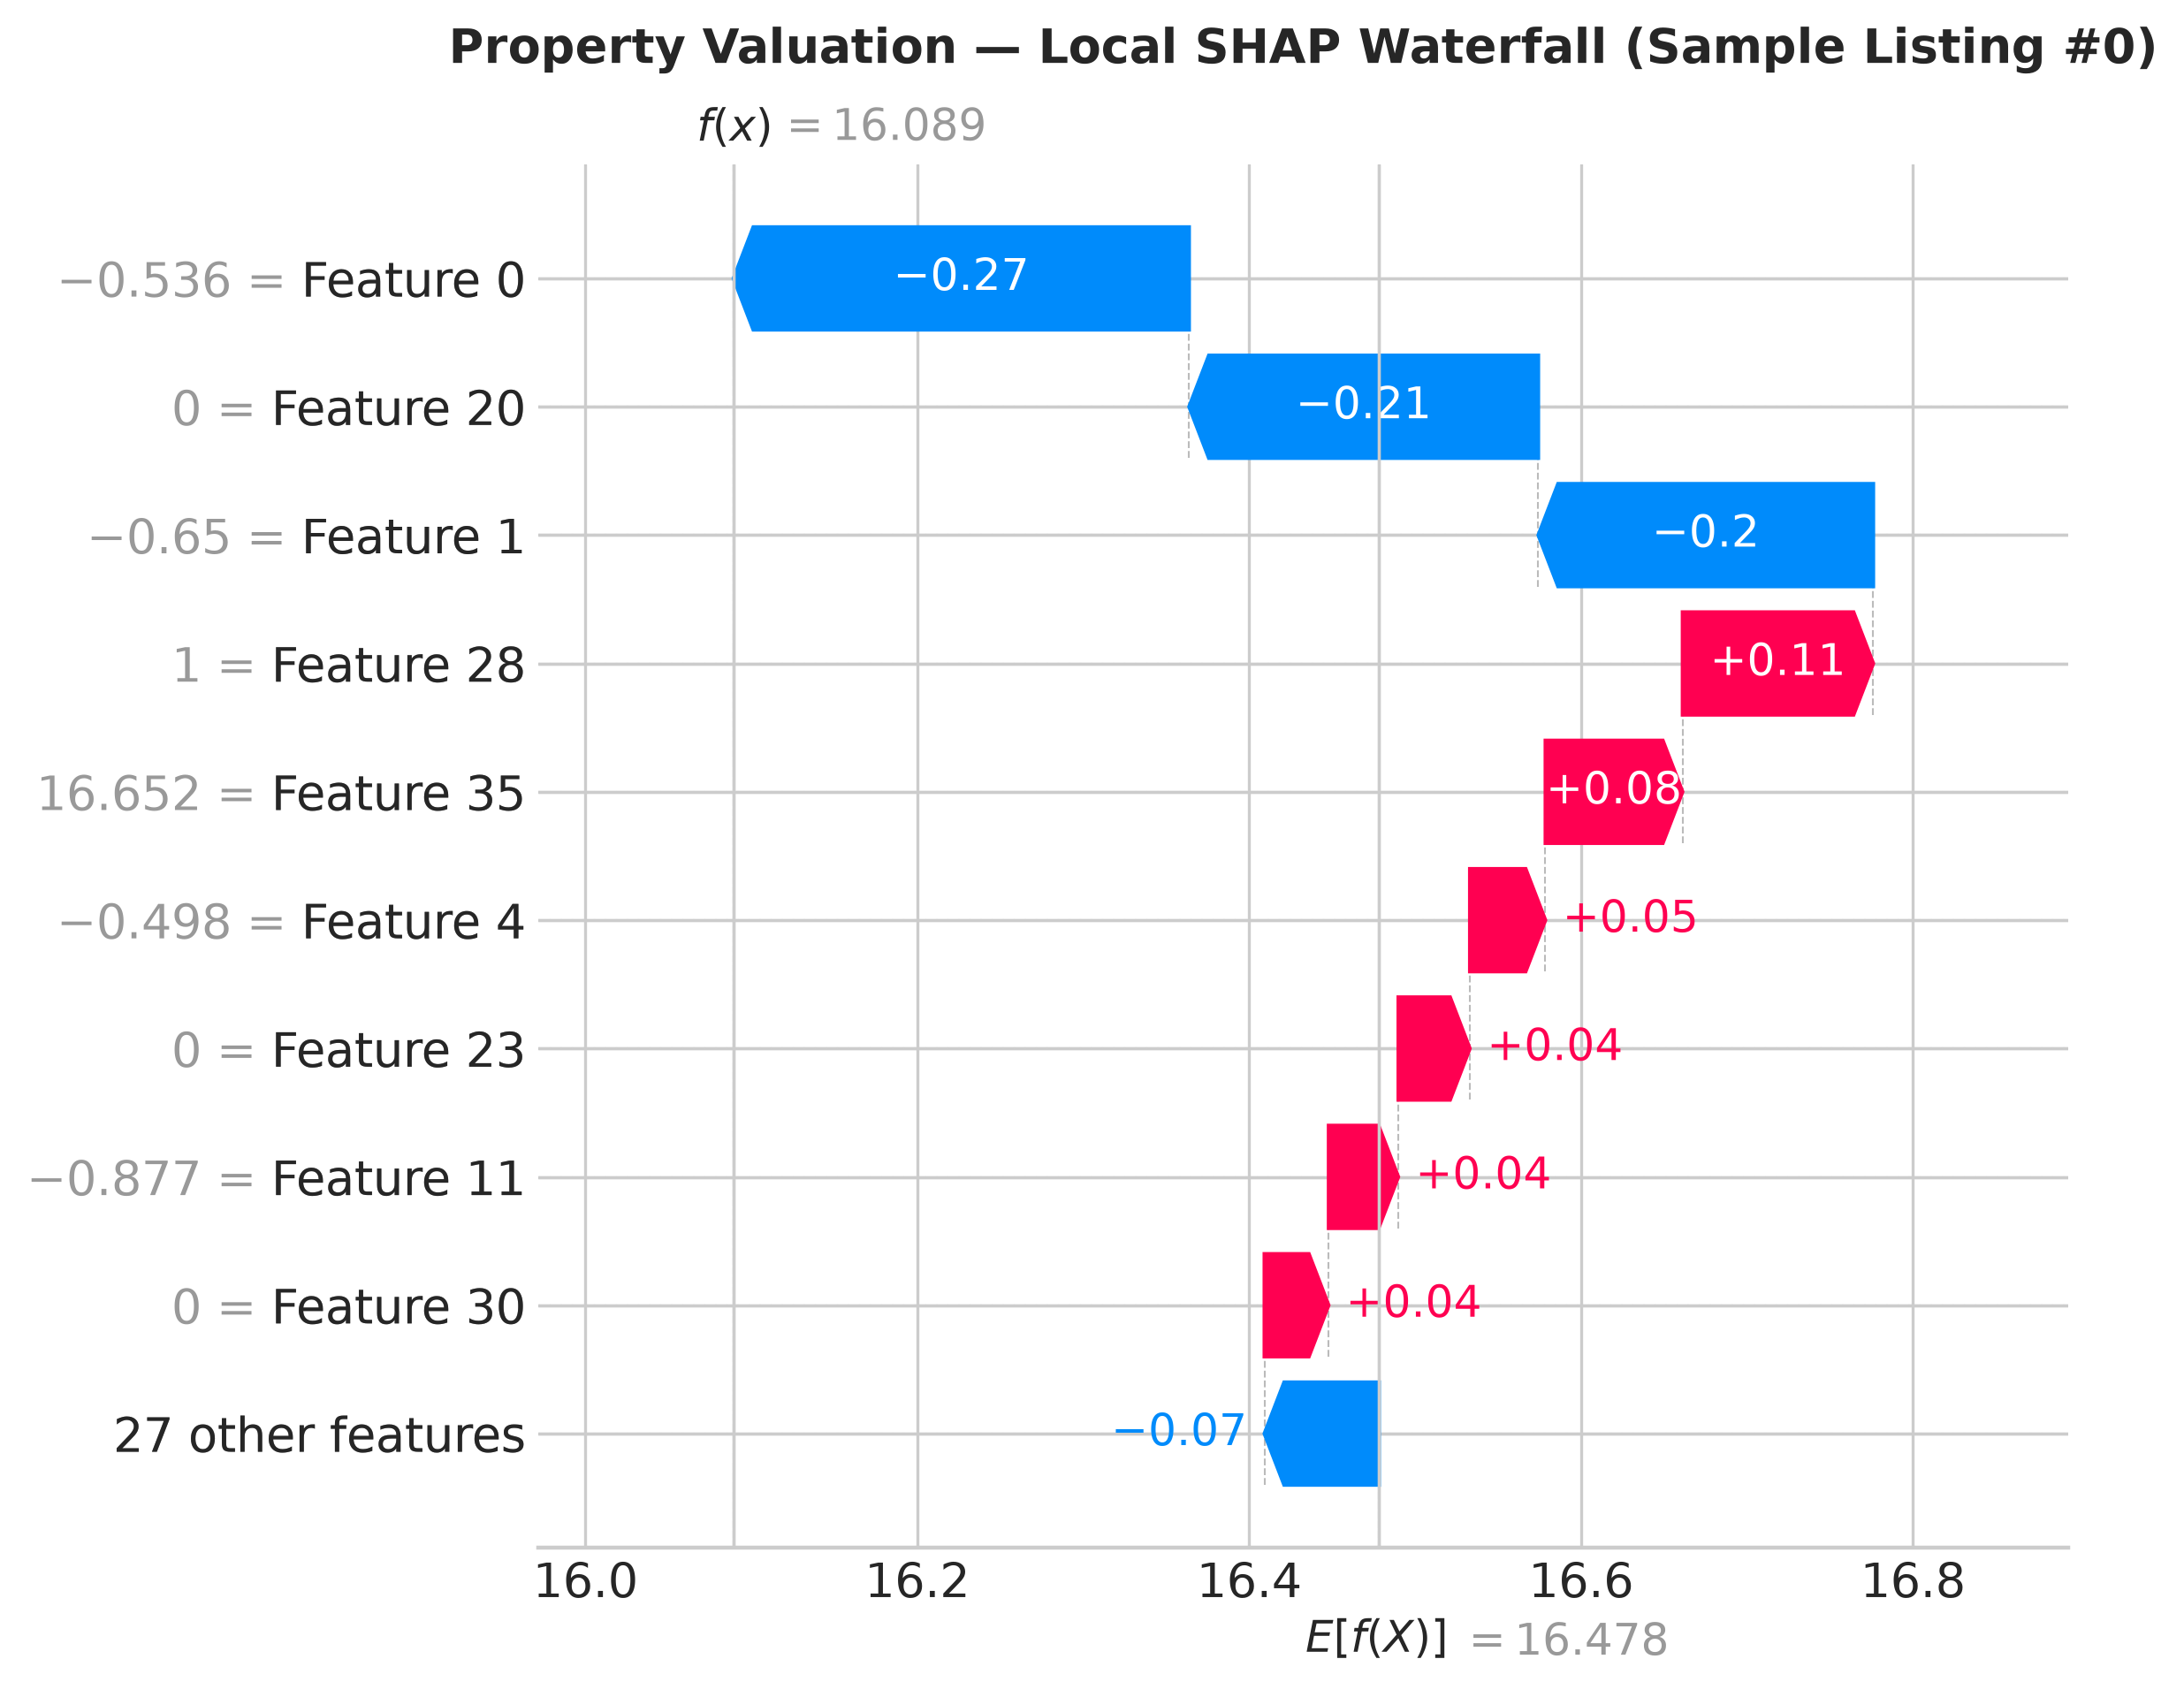

In [7]:
print("=== LEAD SCORING SHAP EXPLANATIONS ===")
display(Image(filename=str(FIGURES_DIR / "05_lead_shap_global_summary.png")))
display(Image(filename=str(FIGURES_DIR / "06_lead_shap_local_waterfall.png")))

print("=== PROPERTY VALUATION SHAP EXPLANATIONS ===")
display(Image(filename=str(FIGURES_DIR / "07_property_shap_global_summary.png")))
display(Image(filename=str(FIGURES_DIR / "08_property_shap_local_waterfall.png")))


## Step 6: Fairness & Unfair Bias Audit
We audit model selection rates and disparate impact ratios across **City** and **Lead Source** to verify demographic parity and prevent systematic exclusion.


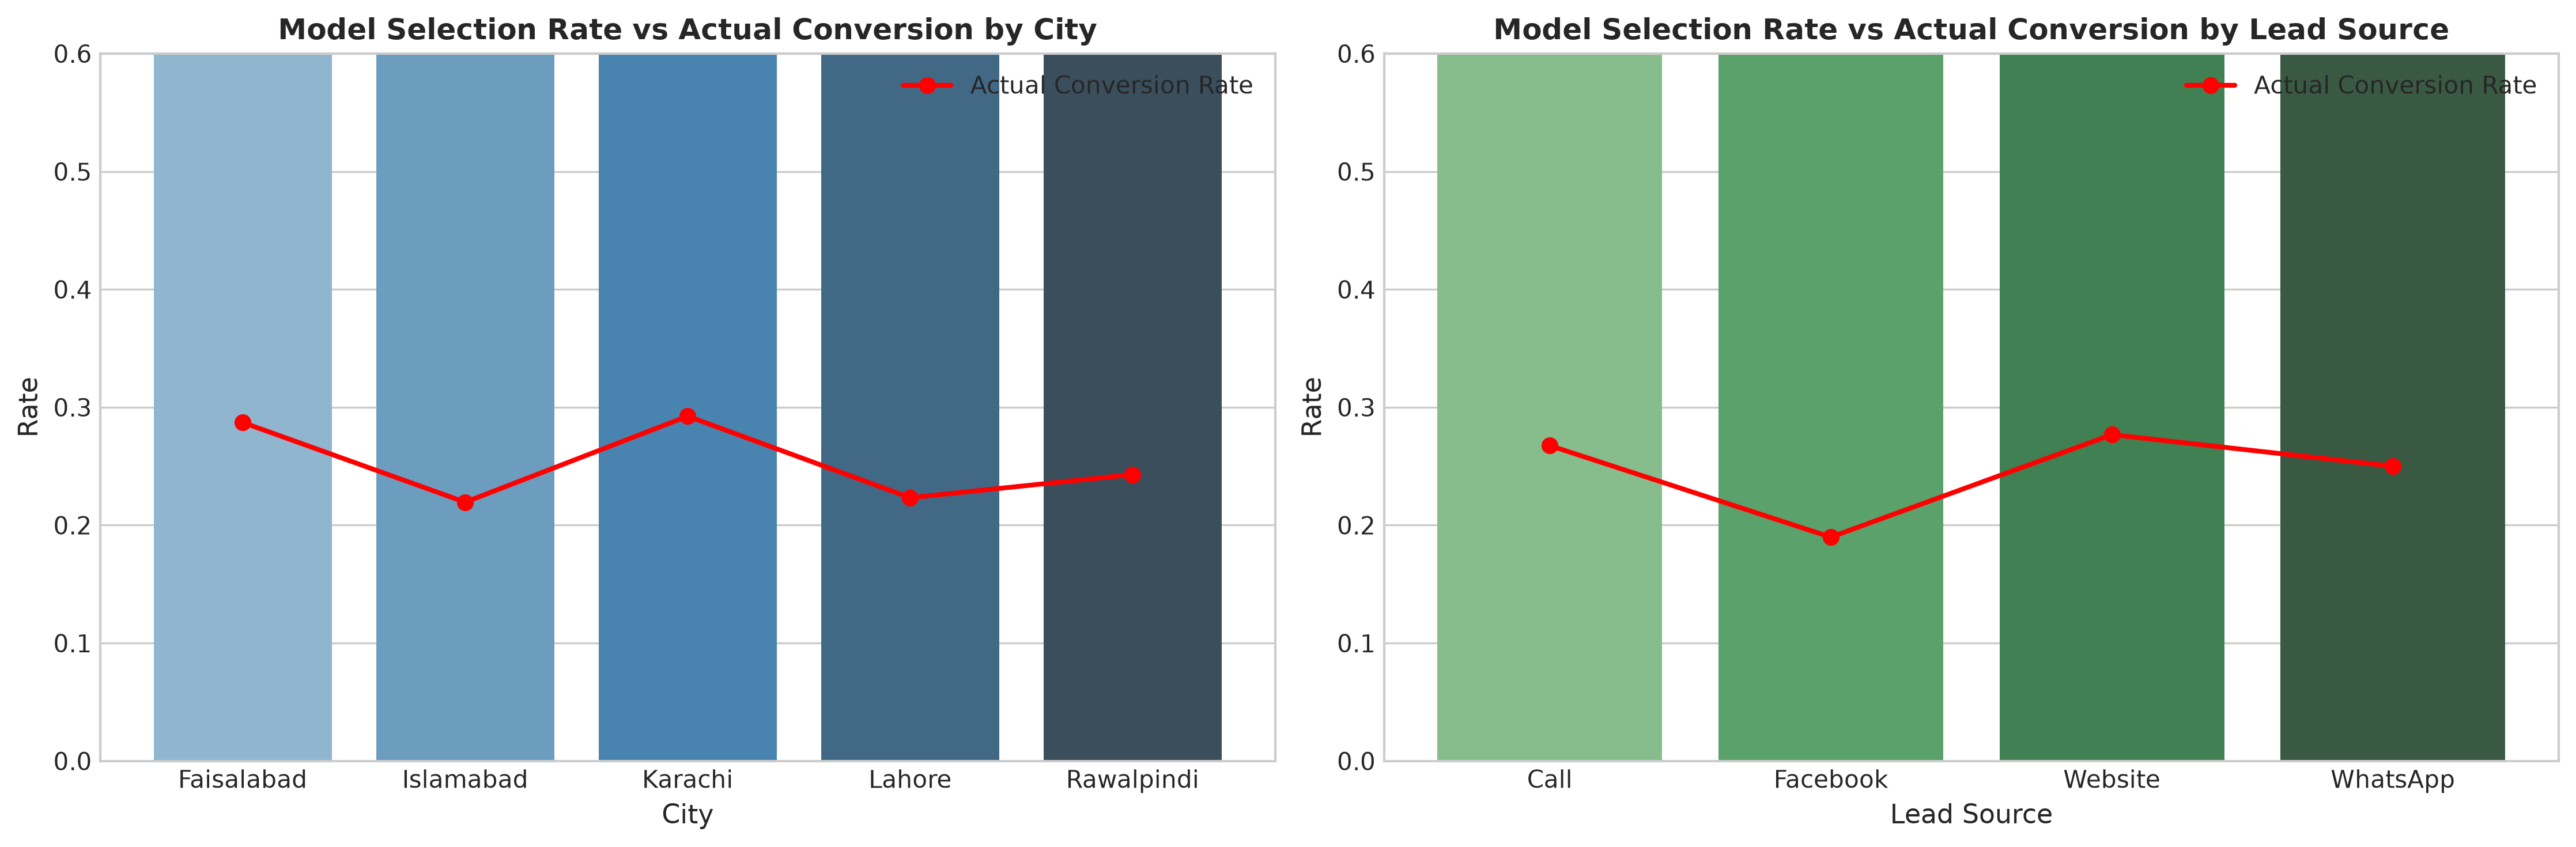

,group,count,actual_conversion_rate,predicted_positive_rate,mean_proba,disparate_impact_ratio,slice_type
0,Faisalabad,101,0.287129,0.782178,0.262661,0.961989,City
1,Islamabad,123,0.219512,0.739837,0.244776,0.909915,City
2,Karachi,106,0.292453,0.773585,0.237655,0.951421,City
3,Lahore,103,0.223301,0.786408,0.252661,0.967191,City
4,Rawalpindi,107,0.242991,0.813084,0.250454,1.000000,City
5,Call,157,0.267516,0.783439,0.239286,0.940127,Lead Source
6,Facebook,79,0.189873,0.620253,0.185798,0.744304,Lead Source
7,Website,112,0.276786,0.785714,0.246246,0.942857,Lead Source
8,WhatsApp,192,0.250000,0.833333,0.285545,1.000000,Lead Source


In [8]:
display(Image(filename=str(FIGURES_DIR / "09_fairness_and_bias_audit.png")))

fairness_df = pd.read_csv(REPORTS_DIR / "fairness_bias_audit.csv")
display(fairness_df)


## Step 7: Production Inference Engine & Week 7 Agent Tool Calling
We test the live inference engine and LangChain `@tool lead_scoring_tool` integrated into `week7-RE_Agent/day5-langgraph-agent`.


In [9]:
from lead_inference import LeadScoringEngine

engine = LeadScoringEngine()

sample_hot_lead = {
    "client_name": "Tariq Mahmood",
    "budget_pkr": 35000000.0,
    "preferred_city": "Islamabad",
    "property_type": "House",
    "purpose": "Buy",
    "number_of_calls": 5,
    "avg_call_duration_mins": 5.8,
    "response_time_hours": 0.2,
    "visit_booked": "Yes",
    "days_since_first_contact": 10,
    "objection_raised": "None",
    "lead_source": "WhatsApp",
}

res = engine.score_lead(sample_hot_lead)
print(res["consultation_statement"])


c:\Users\Haroon\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


[HOT] Tariq Mahmood (Conversion Probability: 91.8%)
- Persona: Serious First-Time Homebuyer
- SLA: Call within 1 hour
- Reason (UrduLish): Yeh lead HOT hai (91.8%) kyun ke Site visit ka confirm hona, Rabtay ki shiddat, Kharidne ka pukhta irada ne conversion imkanat barha diye hain.
- Next Best Action: Assign Senior Closer. Contact immediately to lock property viewing date.
